# Downloading the data

In [25]:
import kagglehub

kagglehub.dataset_download(
    'catherinerasgaitis/mxmh-survey-results',
    path='mxmh_survey_results.csv',
    output_dir='./data'
  )

'./data/mxmh_survey_results.csv'

# Loading and Renaming columns

In [26]:
import pandas as pd

df = pd.read_csv('./data/mxmh_survey_results.csv')
df.head(3)

,Timestamp,Age,Primary streaming service,Hours per day,While working,Instrumentalist,Composer,Fav genre,Exploratory,Foreign languages,...,Frequency [R&B],Frequency [Rap],Frequency [Rock],Frequency [Video game music],Anxiety,Depression,Insomnia,OCD,Music effects,Permissions
0,8/27/2022 19:29:02,18.0,Spotify,3.0,Yes,Yes,Yes,Latin,Yes,Yes,...,Sometimes,Very frequently,Never,Sometimes,3.0,0.0,1.0,0.0,NaN,I understand.
1,8/27/2022 19:57:31,63.0,Pandora,1.5,Yes,No,No,Rock,Yes,No,...,Sometimes,Rarely,Very frequently,Rarely,7.0,2.0,2.0,1.0,NaN,I understand.
2,8/27/2022 21:28:18,18.0,Spotify,4.0,No,No,No,Video game music,No,Yes,...,Never,Rarely,Rarely,Very frequently,7.0,7.0,10.0,2.0,No effect,I understand.


In [27]:
df1 = df.drop(columns=['Timestamp', 'Foreign languages', 'Permissions', 'Exploratory'])
df1.columns

Index(['Age', 'Primary streaming service', 'Hours per day', 'While working',
       'Instrumentalist', 'Composer', 'Fav genre', 'BPM',
       'Frequency [Classical]', 'Frequency [Country]', 'Frequency [EDM]',
       'Frequency [Folk]', 'Frequency [Gospel]', 'Frequency [Hip hop]',
       'Frequency [Jazz]', 'Frequency [K pop]', 'Frequency [Latin]',
       'Frequency [Lofi]', 'Frequency [Metal]', 'Frequency [Pop]',
       'Frequency [R&B]', 'Frequency [Rap]', 'Frequency [Rock]',
       'Frequency [Video game music]', 'Anxiety', 'Depression', 'Insomnia',
       'OCD', 'Music effects'],
      dtype='str')

In [28]:
# Changing column names
df1.columns = ['age', 'streaming_service', 'hours_daily', 'listen_on_work',
               'is_instrumentalist', 'is_composer',
               'fav_genre', 'bpm', 'fr_classical', 'fr_country', 'fr_edm',
               'fr_folk', 'fr_gospel', 'fr_hiphop',
               'fr_jazz', 'fr_kpop', 'fr_latin', 'fr_lofi', 'fr_metal', 'fr_pop',
               'fr_rnb', 'fr_rap', 'fr_rock', 'fr_videogame',
               'anxiety_scr', 'depression_scr', 'insomnia_scr', 'ocd_scr', 'effect']

In [29]:
df1.head(5)

,age,streaming_service,hours_daily,listen_on_work,is_instrumentalist,is_composer,fav_genre,bpm,fr_classical,fr_country,...,fr_pop,fr_rnb,fr_rap,fr_rock,fr_videogame,anxiety_scr,depression_scr,insomnia_scr,ocd_scr,effect
0,18.0,Spotify,3.0,Yes,Yes,Yes,Latin,156.0,Rarely,Never,...,Very frequently,Sometimes,Very frequently,Never,Sometimes,3.0,0.0,1.0,0.0,NaN
1,63.0,Pandora,1.5,Yes,No,No,Rock,119.0,Sometimes,Never,...,Sometimes,Sometimes,Rarely,Very frequently,Rarely,7.0,2.0,2.0,1.0,NaN
2,18.0,Spotify,4.0,No,No,No,Video game music,132.0,Never,Never,...,Rarely,Never,Rarely,Rarely,Very frequently,7.0,7.0,10.0,2.0,No effect
3,61.0,YouTube Music,2.5,Yes,No,Yes,Jazz,84.0,Sometimes,Never,...,Sometimes,Sometimes,Never,Never,Never,9.0,7.0,3.0,3.0,Improve
4,18.0,Spotify,4.0,Yes,No,No,R&B,107.0,Never,Never,...,Sometimes,Very frequently,Very frequently,Never,Rarely,7.0,2.0,5.0,9.0,Improve


# Setting number series if blank to mean
This includes `age`, `hours_daily`, `bpm`, `*_scr`.

In [30]:
# Selecting manually the columns with missing values to fill them with median values
columns_with_missing_values = ['age', 'hours_daily', 'bpm', 'anxiety_scr', 'depression_scr', 'insomnia_scr', 'ocd_scr']

for col in columns_with_missing_values:
    df1[col] = df1[col].fillna(df1[col].median())

In [31]:
# Test before proceding
for col in columns_with_missing_values:
    assert(df1[col].isna().sum() == 0)

print("Cleared missing values in the following columns: ", columns_with_missing_values)

Cleared missing values in the following columns:  ['age', 'hours_daily', 'bpm', 'anxiety_scr', 'depression_scr', 'insomnia_scr', 'ocd_scr']


# Filling NAs of Yes and Nos if any Na
This includes `listen_on_work`, `is_instrumentalist`, `is_composer`.

In [32]:
# Selecting manually the columns with missing values to fill them with constant value 'No'
columns_with_missing_values = ['listen_on_work', 'is_instrumentalist', 'is_composer']

for col in columns_with_missing_values:
    df1[col] = df1[col].fillna('No')

# Test
for col in columns_with_missing_values:
    assert(df1[col].isna().sum() == 0)

print("Filled missing values with 'No' in the following columns: ", columns_with_missing_values)

Filled missing values with 'No' in the following columns:  ['listen_on_work', 'is_instrumentalist', 'is_composer']


# Primary Streaming service fix


In [33]:
df1.streaming_service.unique()

<StringArray>
[                          'Spotify',                           'Pandora',
                     'YouTube Music', 'I do not use a streaming service.',
                       'Apple Music',           'Other streaming service',
                                 nan]
Length: 7, dtype: str

In [34]:
df1.streaming_service = df1.streaming_service.replace(
    {'I do not use a streaming service.': 'Other',
     'Other streaming service': 'Other'}
)

df1.streaming_service = df1.streaming_service.fillna('Other')

# is subset
assert(
  {'Spotify', 'Pandora', 'YouTube Music', 'Other', 'Apple Music'}
  <= set(df1.streaming_service.unique())
)
print("Values in 'streaming_service' column after cleaning:", df1.streaming_service.unique(), sep='\n')

Values in 'streaming_service' column after cleaning:
<StringArray>
['Spotify', 'Pandora', 'YouTube Music', 'Other', 'Apple Music']
Length: 5, dtype: str


# Favorite Genre

In [35]:
df1.fav_genre.unique()

<StringArray>
[           'Latin',             'Rock', 'Video game music',
             'Jazz',              'R&B',            'K pop',
          'Country',              'EDM',          'Hip hop',
              'Pop',              'Rap',        'Classical',
            'Metal',             'Folk',             'Lofi',
           'Gospel']
Length: 16, dtype: str

In [36]:
df1.fav_genre = df1.fav_genre.replace (
    {'Video game music': 'VideoGame',
     'Hip hop': 'HipHop',
     'K pop': 'KPop'
    }
)

df1.fav_genre = df1.fav_genre.fillna('Other')

# is subset
assert({'Latin', 'Rock', 'VideoGame', 'Jazz', 'R&B', 'KPop',
        'Country', 'EDM', 'HipHop', 'Pop', 'Rap', 'Classical',
        'Metal', 'Folk', 'Lofi', 'Gospel'} <= set(df1.fav_genre.unique()))

print("Values in 'fav_genre' column after cleaning:", df1.fav_genre.unique(), sep='\n')

Values in 'fav_genre' column after cleaning:
<StringArray>
[    'Latin',      'Rock', 'VideoGame',      'Jazz',       'R&B',      'KPop',
   'Country',       'EDM',    'HipHop',       'Pop',       'Rap', 'Classical',
     'Metal',      'Folk',      'Lofi',    'Gospel']
Length: 16, dtype: str


# Music Effect

In [37]:
df1.effect.unique()

<StringArray>
[nan, 'No effect', 'Improve', 'Worsen']
Length: 4, dtype: str

In [41]:
df1.effect = df1.effect.fillna('No effect')

# is subset
assert({'No effect', 'Improve', 'Worsen'} <= set(df1.effect.unique()))
print("Setting missing values in 'effect' column to 'No effect'.")

Setting missing values in 'effect' column to 'No effect'.


# Setting frequencies
If na set to Never

In [42]:
# fr_* columns are filled with 'Never' for missing values
columns_with_missing_values = ['fr_classical', 'fr_country', 'fr_edm', 'fr_folk', 'fr_gospel',
                               'fr_hiphop', 'fr_jazz', 'fr_kpop', 'fr_latin', 'fr_lofi', 'fr_metal', 'fr_pop', 'fr_rnb', 'fr_rap', 'fr_rock', 'fr_videogame']

for col in columns_with_missing_values:
    df1[col] = df1[col].fillna('Never')

# test
for col in columns_with_missing_values:
    assert(df1[col].isna().sum() == 0)

print("Filled missing values with 'Never' in the following columns: ", columns_with_missing_values)

Filled missing values with 'Never' in the following columns:  ['fr_classical', 'fr_country', 'fr_edm', 'fr_folk', 'fr_gospel', 'fr_hiphop', 'fr_jazz', 'fr_kpop', 'fr_latin', 'fr_lofi', 'fr_metal', 'fr_pop', 'fr_rnb', 'fr_rap', 'fr_rock', 'fr_videogame']


# Saving cleaned data to file

In [43]:
df1.to_csv('./data/mxmh_survey_results_clean.csv', index=False)

# Asking questions and analysis

In [44]:
df1.head(10)

,age,streaming_service,hours_daily,listen_on_work,is_instrumentalist,is_composer,fav_genre,bpm,fr_classical,fr_country,...,fr_pop,fr_rnb,fr_rap,fr_rock,fr_videogame,anxiety_scr,depression_scr,insomnia_scr,ocd_scr,effect
0,18.0,Spotify,3.0,Yes,Yes,Yes,Latin,156.0,Rarely,Never,...,Very frequently,Sometimes,Very frequently,Never,Sometimes,3.0,0.0,1.0,0.0,No effect
1,63.0,Pandora,1.5,Yes,No,No,Rock,119.0,Sometimes,Never,...,Sometimes,Sometimes,Rarely,Very frequently,Rarely,7.0,2.0,2.0,1.0,No effect
2,18.0,Spotify,4.0,No,No,No,VideoGame,132.0,Never,Never,...,Rarely,Never,Rarely,Rarely,Very frequently,7.0,7.0,10.0,2.0,No effect
3,61.0,YouTube Music,2.5,Yes,No,Yes,Jazz,84.0,Sometimes,Never,...,Sometimes,Sometimes,Never,Never,Never,9.0,7.0,3.0,3.0,Improve
4,18.0,Spotify,4.0,Yes,No,No,R&B,107.0,Never,Never,...,Sometimes,Very frequently,Very frequently,Never,Rarely,7.0,2.0,5.0,9.0,Improve
5,18.0,Spotify,5.0,Yes,Yes,Yes,Jazz,86.0,Rarely,Sometimes,...,Very frequently,Very frequently,Very frequently,Very frequently,Never,8.0,8.0,7.0,7.0,Improve
6,18.0,YouTube Music,3.0,Yes,Yes,No,VideoGame,66.0,Sometimes,Never,...,Rarely,Rarely,Never,Never,Sometimes,4.0,8.0,6.0,0.0,Improve
7,21.0,Spotify,1.0,Yes,No,No,KPop,95.0,Never,Never,...,Sometimes,Sometimes,Rarely,Never,Rarely,5.0,3.0,5.0,3.0,Improve
8,19.0,Spotify,6.0,Yes,No,No,Rock,94.0,Never,Very frequently,...,Never,Never,Never,Very frequently,Never,2.0,0.0,0.0,0.0,Improve
9,18.0,Other,1.0,Yes,No,No,R&B,155.0,Rarely,Rarely,...,Sometimes,Sometimes,Rarely,Sometimes,Sometimes,2.0,2.0,5.0,1.0,Improve


### Effect distribution

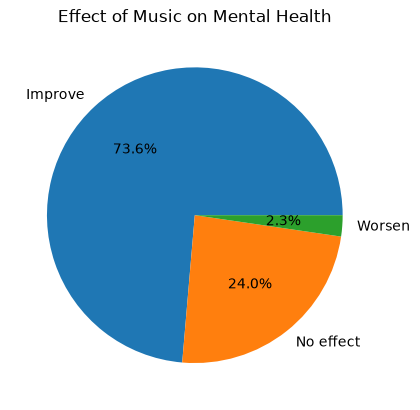

In [51]:
# Effect distribution
effect_dist = \
df1.effect.value_counts(normalize=True) \
   .plot(
      kind='pie',
      title='Effect of Music on Mental Health',
      autopct='%1.1f%%')


### Does effect change by disorder?

<Axes: title={'center': 'Effect of Music on Mental Health for Different Disorders'}, xlabel='effect'>

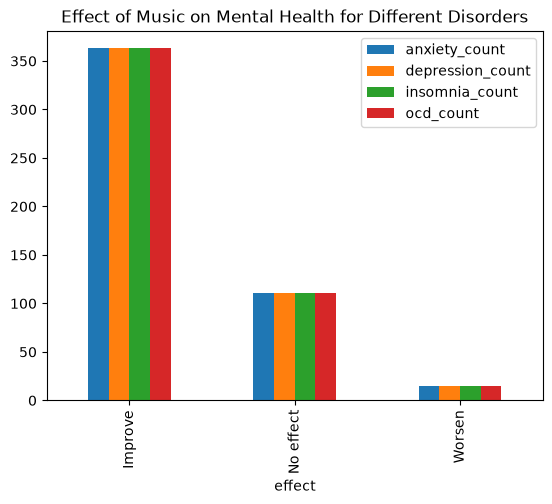

In [69]:
# Effect distribution among different mental disorders
# Considering disorder to be valid if the score >= 7 (arbitrary threshold)
threshold = 7
df_filtered = df1[(df1.anxiety_scr >= threshold) | (df1.depression_scr >= threshold) | (df1.insomnia_scr >= threshold) | (df1.ocd_scr >= threshold)]
df_filtered.groupby('effect').agg(anxiety_count=('anxiety_scr', 'count'),
                                 depression_count=('depression_scr', 'count'),
                                 insomnia_count=('insomnia_scr', 'count'),
                                 ocd_count=('ocd_scr', 'count')) \
.plot(kind='bar', title='Effect of Music on Mental Health for Different Disorders')